# Espejo junto a la muestra: modelo, simulación y redes de localización

Resumen del trabajo con el espejo. Todo lo que muestra sale de código y resultados que ya están en el repo:

- simulación: `simulador_nuevo/simulador.py`, con la geometría de `geometria_espejo.py`;
- redes: evaluaciones de `localizacion/evaluate.py` sobre los tests con espejo `localizacion/datos/test_espejo_sz±1`;
- cotas de Cramér-Rao: `figuras/crlb_espejo.py`.

**No entrena ni corre la red.** Tarda menos de un minuto de punta a punta. La única celda que hay que editar es **Configuración** (la ruta del TIFF real).

In [1]:
import json
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import tifffile
import matplotlib.pyplot as plt
from matplotlib import animation, patheffects
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize, PowerNorm
from matplotlib.lines import Line2D
from IPython.display import HTML, Markdown, display

# raiz del repo: la carpeta que contiene localizacion/train.py (el notebook vive en figuras/)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "localizacion" / "train.py").exists())
for carpeta in ("figuras", "simulador_nuevo"):
    if str(RAIZ / carpeta) not in sys.path:
        sys.path.insert(0, str(RAIZ / carpeta))

import simulador as sim                                   # simulador_nuevo (agrega la raiz al final del sys.path)
from geometria_espejo import GeometriaEspejo
from comun_localizacion import ESTILO, extension_um, barra_escala
import crlb_espejo as ce                                  # figuras/crlb_espejo.py: bootstrap, bordes, carga del test

plt.rcParams.update(ESTILO)
plt.rcParams["animation.embed_limit"] = 40.0              # MB
C_REAL, C_REFLEJO, C_ESPEJO = "#1fc7e6", "#ff9a3c", "#ffd23f"   # cian, naranja, amarillo (como checks/check_espejo.py)

## Configuración

In [2]:
# ============================ Configuracion ============================
# Dato real para la seccion 3. PIXEL_NM_REAL: tamano de pixel en la muestra. El TIFF trae en sus
# metadatos 0.4 um/px, que no coincide con 6.5 um / 66 = 98.5 nm del montaje; se usa 98.48 (confirmar).
RUTA_TIFF_REAL = Path.home() / "Downloads" / "recorte_particula.tif"
PIXEL_NM_REAL = 98.48
FRAME_REAL = 20                 # frame suelto que se muestra
PROMEDIO_REAL = (15, 25)        # frames [inicio, fin) que se promedian para ver mejor la forma
OFFSET_ADU, GAIN_E_ADU = 99.0, 0.46   # Orca Flash 4.0 (los del simulador): e- = (ADU - offset) * gain

# simulacion de la seccion 3: un emisor y su reflejo, parametros elegidos a ojo (no es un ajuste)
D_SIM_UM, Z_SIM_NM, PHI_SIM_DEG = 0.6, 0.0, 0.0   # PHI: azimut de la direccion espejo -> muestra

# redes (seccion 4 y 5): carpetas de evaluate.py sobre el test con espejo de cada signo
C = RAIZ / "localizacion" / "corridas"
SIN_ESPEJO = C / "hypatia_mezcla_renovar_largo_20261027-171202"
CON_ESPEJO = {+1: C / "hypatia_espejo_sz+1_20261109-234610", -1: C / "hypatia_espejo_sz-1_20261109-234650"}
N_BOOT = 2000
SEMILLA = 0

## 1. Montaje y modelo

El espejo es un plano que forma un ángulo **α = 34.0°** con el plano focal, es decir **56° con el eje óptico** (valor medido, redondeado al grado). Ese valor coincide, dentro del redondeo, con el semiángulo del cono de colección del objetivo, arcsin(NA/n) = arcsin(1.1/1.333) = 55.6°. Cada emisor real en **p** produce una imagen virtual (el reflejo) en

$$p' = p_0 + R\,(p - p_0),\qquad R = I - 2\,n n^\top,\qquad n = \sin\alpha\,\hat m - s\cos\alpha\,\hat z,$$

donde $p_0$ es un punto del espejo, $\hat m$ la dirección lateral que va de la línea del espejo hacia la muestra, $\hat t$ la dirección de esa línea, y $s$ = `signo_inclinacion` · `signo_z` (+1 por defecto). Si $d$ es la distancia del real al plano del espejo, el reflejo está a $2d\sin\alpha$ en la imagen y a $2d\cos\alpha$ en z.

**Por qué el movimiento del reflejo queda ligado.** $p'$ es una función afín de $p$, así que el reflejo no tiene grados de libertad propios: $\Delta p' = R\,\Delta p$. En coordenadas $(t, m, z)$:

$$\Delta t' = \Delta t,\qquad \Delta m' = \cos 2\alpha\,\Delta m + s\sin 2\alpha\,\Delta z,\qquad \Delta z' = s\sin 2\alpha\,\Delta m - \cos 2\alpha\,\Delta z,$$

con $\cos 2\alpha = 0.37$ y $\sin 2\alpha = 0.93$. En el simulador cada subposición del reflejo (también dentro de la exposición, para el desenfoque de movimiento) es el reflejo de la del real, el espejo actúa como una pared reflectante más del movimiento browniano, y el reflejo se dibuja con `ratio_reflejo` × N fotones (0.8). Una consecuencia: la posición lateral del reflejo a lo largo de $\hat m$ cambia 0.93 nm por cada nm de z del real, así que el reflejo es una segunda vista, lateral, de z.

alpha = 34.0 grados -> 56.0 grados del eje optico;  arcsin(NA/n) = 55.6 grados
cos 2a = 0.375, sin 2a = 0.927


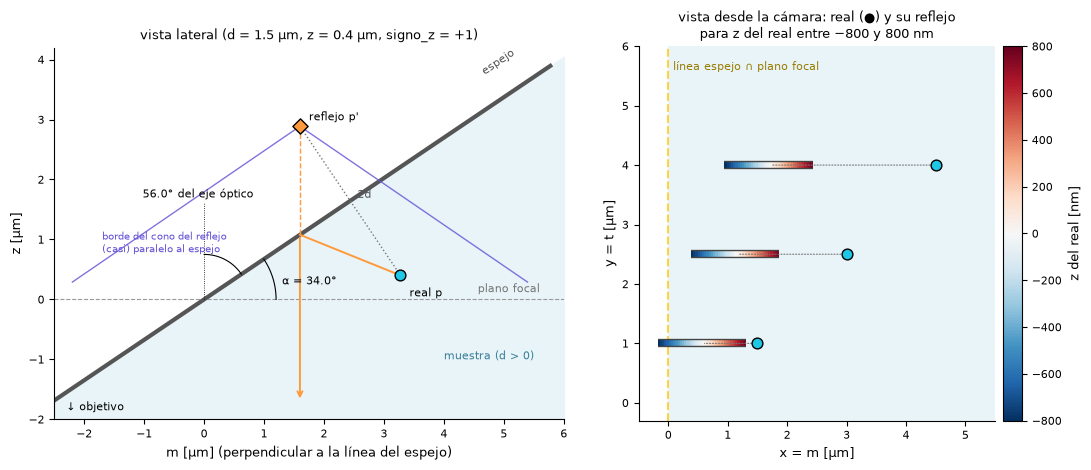

In [3]:
ALFA, NA, N_MEDIO = sim.Config().angulo_espejo_deg, 1.1, 1.333   # alpha = 90 - 56 (medido, redondeado)
TH_MAX = np.degrees(np.arcsin(NA / N_MEDIO))               # semiangulo del cono de coleccion
geo = GeometriaEspejo(ALFA, 0.0, [0.0, 0.0, 0.0], -800.0, 800.0, 1, 1)   # phi = 0: m = +x
a = geo.alpha
print(f"alpha = {ALFA} grados -> {90 - ALFA:.1f} grados del eje optico;  arcsin(NA/n) = {TH_MAX:.1f} grados")
print(f"cos 2a = {np.cos(2 * a):.3f}, sin 2a = {np.sin(2 * a):.3f}")


def real_a_distancia(d_nm, z_nm, s_t=0.0):
    # punto [nm] a distancia d del plano y altura z, sobre la recta p0 + s_m m (+ s_t t)
    s_m = (d_nm + np.cos(a) * z_nm) / np.sin(a)
    return s_m * geo.m + s_t * geo.t + np.array([0.0, 0.0, z_nm])


fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw=dict(width_ratios=[1.25, 1]))

# --- vista lateral (plano m-z, convencion signo_z = +1: +z se aleja del objetivo) ---
u = np.array([np.cos(a), np.sin(a)])                       # direccion del espejo en (m, z)
L = np.array([-3.2, 7.0])
ax.fill_between([-2.5, 6], [-2.5 * np.tan(a), 6 * np.tan(a)], -2.0, color="#e8f4f8", zorder=0)
ax.plot(L * u[0], L * u[1], color="#555555", lw=3, solid_capstyle="butt", zorder=2)
ax.axhline(0, color="#999999", lw=0.8, ls="--", zorder=1)
p = real_a_distancia(1500.0, 400.0) / 1000                 # um
pr = geo.reflejar_nm(p * 1000) / 1000
P, Pr = p[[0, 2]], pr[[0, 2]]
pie = P - (P - Pr) / 2                                     # pie de la perpendicular sobre el espejo
ax.plot(*zip(P, Pr), ls=":", color="#777777", lw=1)
ax.text(*(P + Pr) / 2 + np.array([0.12, 0.05]), f"2d", fontsize=8, color="#555555")
# rayo vertical desde el reflejo virtual: corta el espejo en q y sigue hacia el objetivo
q = np.array([Pr[0], Pr[0] * np.tan(a)])
ax.plot(*zip(P, q), color=C_REFLEJO, lw=1.4)
ax.annotate("", xy=(q[0], -1.7), xytext=q, arrowprops=dict(arrowstyle="->", color=C_REFLEJO, lw=1.4))
ax.plot(*zip(Pr, q), color=C_REFLEJO, lw=1, ls="--")
# cono de coleccion del reflejo virtual (semiangulo arcsin(NA/n) = 55.6): un borde casi paralelo al espejo (56 del eje)
th = np.radians(TH_MAX)
for sgn, ls in ((-1, "-"), (1, "-")):
    dir_ = np.array([sgn * np.sin(th), -np.cos(th)])
    ax.plot(*zip(Pr, Pr + 4.6 * dir_), color="#6250d6", lw=1, ls=ls, alpha=0.8)
ax.text(Pr[0] - 3.3, Pr[1] - 2.1, "borde del cono del reflejo\n(casi) paralelo al espejo", fontsize=7.5, color="#6250d6")
ax.scatter(*P, s=60, color=C_REAL, edgecolor="k", zorder=5)
ax.scatter(*Pr, s=60, color=C_REFLEJO, edgecolor="k", marker="D", zorder=5)
ax.text(P[0] + 0.15, P[1] - 0.35, "real p", fontsize=8)
ax.text(Pr[0] + 0.15, Pr[1] + 0.1, "reflejo p'", fontsize=8)
# angulos
t_arc = np.linspace(0, a, 30)
ax.plot(1.2 * np.cos(t_arc), 1.2 * np.sin(t_arc), color="k", lw=0.8)
ax.text(1.3, 0.25, f"α = {ALFA}°", fontsize=8)
t_arc = np.linspace(a, np.pi / 2, 30)
ax.plot(0.75 * np.cos(t_arc), 0.75 * np.sin(t_arc), color="k", lw=0.8)
ax.plot([0, 0], [0, 1.6], color="k", lw=0.6, ls=":")
ax.text(-0.1, 1.7, f"{90 - ALFA:.1f}° del eje óptico", fontsize=8, ha="center")
ax.text(5.6, 0.12, "plano focal", fontsize=8, ha="right", color="#777777")
ax.text(4.6, 3.75, "espejo", fontsize=8, rotation=ALFA, color="#555555")
ax.text(4.0, -1.0, "muestra (d > 0)", fontsize=8, color="#3a7f99")
ax.text(-2.3, -1.85, "↓ objetivo", fontsize=8)
ax.set_xlim(-2.5, 6); ax.set_ylim(-2, 4.2); ax.set_aspect("equal")
ax.set_xlabel("m [µm] (perpendicular a la línea del espejo)"); ax.set_ylabel("z [µm]")
ax.set_title(f"vista lateral (d = 1.5 µm, z = 0.4 µm, signo_z = +1)")

# --- vista desde la camara (plano x-y): posicion del reflejo segun la z del real ---
bx.axvspan(0, 6, color="#e8f4f8", zorder=0)
bx.axvline(0, color=C_ESPEJO, ls="--", lw=1.5)
norm_z = Normalize(-800, 800)
zs = np.linspace(-800, 800, 41)
for k, (m_um, t_um) in enumerate([(1.5, 1.0), (3.0, 2.5), (4.5, 4.0)]):
    pts = np.array([geo.reflejar_nm(np.array([m_um * 1000, t_um * 1000, z])) for z in zs]) / 1000
    seg = np.stack([pts[:-1, :2], pts[1:, :2]], axis=1)
    lc_z = LineCollection(seg, cmap="RdBu_r", norm=norm_z, array=zs[:-1], lw=4, capstyle="butt")
    lc_z.set_path_effects([patheffects.withStroke(linewidth=6, foreground="#444444")])
    bx.add_collection(lc_z)
    bx.scatter(m_um, t_um, s=60, color=C_REAL, edgecolor="k", zorder=5)
    bx.annotate("", xy=pts[20, :2], xytext=(m_um, t_um), arrowprops=dict(arrowstyle="-", color="#777777", lw=0.8, ls=":"))
sm = plt.cm.ScalarMappable(norm=norm_z, cmap="RdBu_r")
cb = fig.colorbar(sm, ax=bx, fraction=0.05, pad=0.02); cb.set_label("z del real [nm]")
bx.text(0.08, 5.6, "línea espejo ∩ plano focal", fontsize=8, color="#9a7d00")
bx.set_xlim(-0.5, 5.5); bx.set_ylim(-0.3, 6); bx.set_aspect("equal")
bx.set_xlabel("x = m [µm]"); bx.set_ylabel("y = t [µm]")
bx.set_title("vista desde la cámara: real (●) y su reflejo\npara z del real entre −800 y 800 nm")
fig.tight_layout()
plt.show()

A la izquierda, el reflejo es la imagen especular del real respecto del plano del espejo. El rayo naranja sale del real, se refleja y llega al objetivo como si viniera de $p'$. El cono de colección del reflejo (violeta, semiángulo 55.6°) tiene un borde casi paralelo al espejo: 55.6° frente a los 56° medidos, una diferencia dentro del redondeo de la medición. Los rayos cercanos a ese borde llegan al espejo de forma rasante y lejos del emisor, así que con un espejo finito parte de ellos se pierde. Ese **recorte de pupila del reflejo no está modelado** (sección 7).

A la derecha, la vista desde la cámara: con el real fijo en el plano de la imagen, su z desplaza el reflejo a lo largo de $\hat m$, unos 1.5 µm para todo el rango de ±800 nm. Con `signo_z = −1` el desplazamiento va en sentido contrario.

## 2. Simulación

Un video de `simulador_nuevo` con el espejo activo: 6 emisores con fotones altos (15 000–30 000) y fondo bajo (5–10 fotones/px), para que se vean. Los emisores parten a menos de 4 µm del plano del espejo, como en los datos de entrenamiento. La línea amarilla es la intersección del espejo con el plano focal. Hay ruido de cámara Orca (Poisson + lectura) y 10 Hz.

banco K = 176 px, z en [-800, 8200] nm; 6 emisores
 particle_id  x_px  y_px   z_nm  photons  z_reflejo_nm
           0  46.4  54.0  451.3  17460.7        2971.3
           1  47.5  31.9 -536.2  17428.5        3443.3
           2  14.7  43.7  172.5  29544.0         178.0
           3  55.8  57.2  -77.9  27067.9        4025.3
           4  39.7  55.6  155.6  22845.2        2472.6
           5  33.6  38.6  168.1  17725.8        1908.1


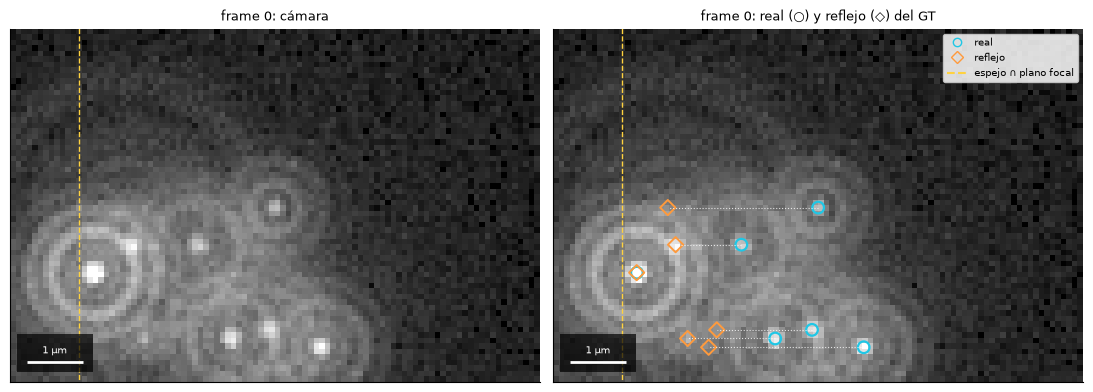

In [4]:
cfg_v = sim.Config(usar_espejo=True, H=64, W=96, n_videos=1, n_frames=40, espejo_punto_px=(12.0, 32.0),
                   orientacion_espejo_deg=0.0, fotones_rango=(15000.0, 30000.0), fondo_rango=(5.0, 10.0),
                   fondo_no_uniforme=False, n_emisores_rango=(5, 7), dist_max_espejo_um=4.0,
                   D_rango_um2_s=(0.05, 0.3), seed=3)
banco = sim.BancoPSF(cfg_v)
video, gt_v = sim.generar_video(cfg_v, banco, video_id=0)
px_um = cfg_v.pixel_nm / 1000
e_v = sim.adu_a_electrones(video.astype(float), cfg_v)
ext_v = extension_um(cfg_v.H, cfg_v.W, px_um)
norma_v = PowerNorm(0.5, vmin=np.percentile(e_v, 1), vmax=np.percentile(e_v, 99.95))
esp_v = sim.Espejo(cfg_v)
q0 = esp_v.punto_en_z_nm(0.0) / 1000                       # linea espejo ∩ plano focal [um]
linea_v = q0[:2] + np.outer([-20, 20], esp_v.t[:2])
print(f"banco K = {banco.K} px, z en [{banco.z_grid[0]:.0f}, {banco.z_grid[-1]:.0f}] nm; "
      f"{gt_v.particle_id.nunique()} emisores")
print(gt_v[gt_v.frame == 0][["particle_id", "x_px", "y_px", "z_nm", "photons", "z_reflejo_nm"]]
      .round(1).to_string(index=False))


def panel_video(ax, img_e, marcas, gt_f=None):
    im = ax.imshow(img_e, cmap="gray", norm=norma_v, extent=ext_v, interpolation="nearest")
    ax.plot(*linea_v.T, color=C_ESPEJO, ls="--", lw=1)
    ax.set_xlim(ext_v[0], ext_v[1]); ax.set_ylim(ext_v[2], ext_v[3])
    ax.set_xticks([]); ax.set_yticks([])
    barra_escala(ax, ext_v)
    art = None
    if marcas:
        segs = np.stack([gt_f[["x_px", "y_px"]].to_numpy(), gt_f[["x_reflejo_px", "y_reflejo_px"]].to_numpy()], 1) * px_um
        lc = LineCollection(segs, colors="white", lw=0.8, linestyles=":", alpha=0.8)
        ax.add_collection(lc)
        sr = ax.scatter(gt_f.x_px * px_um, gt_f.y_px * px_um, s=70, facecolors="none", edgecolors=C_REAL, lw=1.6)
        sf = ax.scatter(gt_f.x_reflejo_px * px_um, gt_f.y_reflejo_px * px_um, s=60, marker="D",
                        facecolors="none", edgecolors=C_REFLEJO, lw=1.4)
        art = (lc, sr, sf)
    return im, art


fig, axs = plt.subplots(1, 2, figsize=(11, 3.9))
g0 = gt_v[gt_v.frame == 0]
panel_video(axs[0], e_v[0], False)
panel_video(axs[1], e_v[0], True, g0)
axs[0].set_title("frame 0: cámara")
axs[1].set_title("frame 0: real (○) y reflejo (◇) del GT")
axs[1].legend(handles=[Line2D([], [], marker="o", ls="none", mfc="none", mec=C_REAL, label="real"),
                       Line2D([], [], marker="D", ls="none", mfc="none", mec=C_REFLEJO, label="reflejo"),
                       Line2D([], [], color=C_ESPEJO, ls="--", label="espejo ∩ plano focal")],
              loc="upper right", fontsize=7, framealpha=0.85)
fig.tight_layout()
plt.show()

In [5]:
# animacion de los 40 frames (4 s a 10 Hz), embebida en el notebook
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.4), dpi=72)
im0, _ = panel_video(axs[0], e_v[0], False)
im1, (lc, sr, sf) = panel_video(axs[1], e_v[0], True, g0)
titulo = fig.suptitle("")
fig.tight_layout()


def cuadro(t):
    g = gt_v[gt_v.frame == t]
    im0.set_data(e_v[t]); im1.set_data(e_v[t])
    xy, xyr = g[["x_px", "y_px"]].to_numpy() * px_um, g[["x_reflejo_px", "y_reflejo_px"]].to_numpy() * px_um
    sr.set_offsets(xy); sf.set_offsets(xyr); lc.set_segments(np.stack([xy, xyr], 1))
    titulo.set_text(f"t = {t * cfg_v.dt_s:.1f} s")
    return im0, im1, sr, sf, lc


anim = animation.FuncAnimation(fig, cuadro, frames=cfg_v.n_frames, interval=1000 * cfg_v.dt_s, blit=False)
plt.close(fig)
HTML(anim.to_jshtml(default_mode="loop"))

El reflejo de cada partícula se mueve con ella: a lo largo de la línea del espejo ($\hat t$) el desplazamiento es el mismo, y perpendicular a ella ($\hat m$) mezcla el movimiento lateral y el axial. Los reflejos lejanos al espejo están muy desenfocados (z' de hasta ~4 µm en este video) y se ven como anillos tenues.

## 3. Comparación con un dato real

Un frame real y el promedio de unos pocos frames (la partícula se mueve, así que el promedio emborrona un poco), al lado de la simulación de un emisor y su reflejo con los dos signos de `signo_z`. Todos los paneles tienen el mismo tamaño físico en µm. La simulación promedia el mismo número de frames que el panel real, con el mismo fondo y el mismo flujo dentro de un disco de 1.5 µm. El dato real tiene un halo y un fondo no uniforme, así que su flujo es una estimación gruesa. La geometría simulada (d, z del real, orientación) se eligió a ojo en la celda **Configuración**: es una comparación cualitativa de forma, no un ajuste.

real: 1340 frames de 64x64 px = 6.30 um de lado
flujo en un disco de 1.5 um (real + reflejo): frame 20 ~4004 fotones, fondo 14.3 fotones/px;  promedio 15-24: ~3597 fotones, fondo 14.8
simulacion: N del real = 2912 (signo_z +1), 3085 (signo_z -1), reflejo 0.8 N, mismo flujo en el disco y mismo fondo que el promedio real


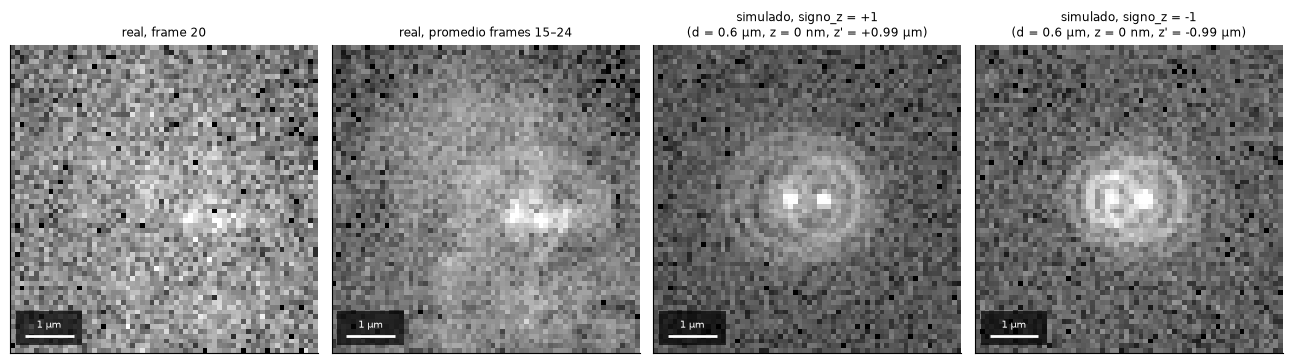

In [6]:
from scipy.ndimage import gaussian_filter


def a_electrones(adu):
    return (np.asarray(adu, float) - OFFSET_ADU) * GAIN_E_ADU


R_DISCO_UM = 1.5                # radio del disco donde se iguala el flujo real <-> simulado


def disco(forma, centro, r_px):
    yy, xx = np.mgrid[:forma[0], :forma[1]]
    return (xx - centro[0]) ** 2 + (yy - centro[1]) ** 2 <= r_px ** 2


def flujo_y_fondo(img_e, px_nm, borde=4):
    # fondo: mediana del borde de la imagen [fotones/px]; flujo: suma de (e - fondo) en un disco de
    # R_DISCO_UM alrededor del maximo de la imagen suavizada (real + reflejo). El dato real tiene un
    # halo y fondo no uniforme, asi que el flujo total no esta bien definido: es una estimacion gruesa.
    from scipy.ndimage import gaussian_filter
    marco = np.concatenate([img_e[:borde].ravel(), img_e[-borde:].ravel(), img_e[:, :borde].ravel(), img_e[:, -borde:].ravel()])
    b = float(np.median(marco))
    cy, cx = np.unravel_index(gaussian_filter(img_e, 2).argmax(), img_e.shape)
    return float((img_e - b)[disco(img_e.shape, (cx, cy), R_DISCO_UM * 1000 / px_nm)].sum()), b


def simular_par(signo_z, flujo, b, lado_px, n_prom, rng):
    # emisor real a D_SIM_UM del espejo y z = Z_SIM_NM, y su reflejo (0.8 N), centrados en la imagen,
    # con N tal que el flujo en el mismo disco que en el dato real sea igual; n_prom frames
    # independientes promediados (como el promedio del dato real). Devuelve (imagen e-, z', N).
    g = GeometriaEspejo(ALFA, PHI_SIM_DEG, [0.0, 0.0, 0.0], -800.0, 800.0, signo_z, 1)
    s = signo_z
    p = ((D_SIM_UM * 1000 + s * np.cos(g.alpha) * Z_SIM_NM) / np.sin(g.alpha)) * g.m + np.array([0, 0, Z_SIM_NM])
    pr = g.reflejar_nm(p)
    c = (lado_px - 1) / 2 - ((p[:2] + pr[:2]) / 2) / cfg_v.pixel_nm
    unidad = np.zeros((lado_px, lado_px))                 # N = 1
    banco.colocar(unidad, *(p[:2] / cfg_v.pixel_nm + c), p[2], 1.0)
    banco.colocar(unidad, *(pr[:2] / cfg_v.pixel_nm + c), pr[2], cfg_v.ratio_reflejo)
    centro = np.unravel_index(gaussian_filter(unidad, 2).argmax(), unidad.shape)[::-1]
    N = flujo / unidad[disco(unidad.shape, centro, R_DISCO_UM * 1000 / cfg_v.pixel_nm)].sum()
    cfg_c = replace(cfg_v, H=lado_px, W=lado_px)
    frames = [sim.adu_a_electrones(sim.aplicar_camara(b + N * unidad, cfg_c, rng).astype(float), cfg_c)
              for _ in range(n_prom)]
    return np.mean(frames, axis=0), pr[2], N


if not RUTA_TIFF_REAL.exists():
    display(Markdown(f"**No se encontró el TIFF real** (`{RUTA_TIFF_REAL}`): cambiar `RUTA_TIFF_REAL` en Configuración."))
else:
    real = tifffile.imread(RUTA_TIFF_REAL)
    real = real[None] if real.ndim == 2 else real
    f_e = a_electrones(real[FRAME_REAL])
    i0, i1 = PROMEDIO_REAL
    p_e = a_electrones(real[i0:i1].mean(axis=0))
    F1, b1 = flujo_y_fondo(f_e, PIXEL_NM_REAL)
    Fp, bp = flujo_y_fondo(p_e, PIXEL_NM_REAL)
    lado_um = real.shape[-1] * PIXEL_NM_REAL / 1000
    lado_sim = int(round(lado_um * 1000 / cfg_v.pixel_nm))
    rng = np.random.default_rng(SEMILLA)
    sims = {s: simular_par(s, Fp, bp, lado_sim, i1 - i0, rng) for s in (+1, -1)}
    print(f"real: {real.shape[0]} frames de {real.shape[1]}x{real.shape[2]} px = {lado_um:.2f} um de lado")
    print(f"flujo en un disco de {R_DISCO_UM} um (real + reflejo): frame {FRAME_REAL} ~{F1:.0f} fotones, fondo "
          f"{b1:.1f} fotones/px;  promedio {i0}-{i1 - 1}: ~{Fp:.0f} fotones, fondo {bp:.1f}")
    print("simulacion: N del real = " + ", ".join(f"{sims[s][2]:.0f} (signo_z {s:+d})" for s in (+1, -1))
          + f", reflejo 0.8 N, mismo flujo en el disco y mismo fondo que el promedio real")

    paneles = [(f_e, f"real, frame {FRAME_REAL}", lado_um, real.shape[-1]),
               (p_e, f"real, promedio frames {i0}–{i1 - 1}", lado_um, real.shape[-1])]
    for s in (+1, -1):
        img, zr, _ = sims[s]
        paneles.append((img, f"simulado, signo_z = {s:+d}\n(d = {D_SIM_UM} µm, z = {Z_SIM_NM:.0f} nm, z' = {zr / 1000:+.2f} µm)",
                        lado_um, lado_sim))
    fig, axs = plt.subplots(1, 4, figsize=(13, 3.7))
    for ax, (img, tit, lu, n) in zip(axs, paneles):
        ext = extension_um(n, n, lu / n)
        ax.imshow(img, cmap="gray", extent=ext, interpolation="nearest",
                  norm=PowerNorm(0.5, vmin=np.percentile(img, 1), vmax=np.percentile(img, 99.8)))
        barra_escala(ax, ext)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(tit, fontsize=8.5)
    fig.tight_layout()
    plt.show()

Qué mirar: la separación entre los dos lóbulos y de qué lado aparecen los anillos. Con `signo_z = +1` el reflejo queda en +z', donde la PSF esférica del código gana anillos. Con `signo_z = −1` queda en −z', donde la PSF es compacta. Esta comparación sola no decide el signo, porque el recorte de pupila (no modelado) también cambia la forma del reflejo. Lo decidirá un z-stack de una bead (sección 7).

## 4. Red sin espejo vs red con espejo, sobre el mismo test

- **Red sin espejo:** `mezcla_renovar_largo`, entrenada sin espejo y con un canal.
- **Redes con espejo:** `espejo_sz±1`, entrenadas con espejo (geometría aleatoria por muestra, α ∈ [29.4°, 39.4°], centrado en el valor anterior de 34.4°) y con un segundo canal de entrada, la distancia a la línea del espejo. Cada una se evalúa sobre el test con espejo de su signo.

Los tests tienen 2000 imágenes de 64 × 64 px, con 1–12 emisores y sus reflejos. Una detección es correcta si cae a menos de 150 nm laterales y 300 nm en z. Un FP está "sobre un reflejo" si cae a menos de 150 nm laterales de un reflejo.

In [7]:
def evaluacion(corrida, signo):
    return corrida / f"evaluacion_test_espejo_sz{signo:+d}"


REDES = {+1: [("sin espejo", evaluacion(SIN_ESPEJO, +1)), ("con espejo (sz+1)", evaluacion(CON_ESPEJO[+1], +1))],
         -1: [("sin espejo", evaluacion(SIN_ESPEJO, -1)), ("con espejo (sz-1)", evaluacion(CON_ESPEJO[-1], -1))]}
faltan = [str(c) for redes in REDES.values() for _, c in redes if not (c / "resumen.yaml").exists()]
assert not faltan, f"faltan evaluaciones (correr localizacion/evaluate.py): {faltan}"

filas = []
for signo, redes in REDES.items():
    for nombre, carpeta in redes:
        r = yaml.safe_load(open(carpeta / "resumen.yaml"))
        m, e = r["metricas"], r["espejo"]
        filas.append({"test": f"sz{signo:+d}", "red": nombre, "recall": m["recall"], "precisión": m["precision"],
                      "FP": e["fp"], "FP sobre reflejos": f"{e['fp_sobre_reflejo']} ({100 * e['fraccion_fp_sobre_reflejo']:.0f}%)",
                      "reflejos con FP": f"{100 * e['fraccion_reflejos_con_fp']:.1f}%",
                      "RMSE lateral [nm]": m["rmse_lat_nm"], "RMSE z [nm]": m["rmse_z_nm"]})
tabla = pd.DataFrame(filas).set_index(["test", "red"])
display(tabla.style.format({"recall": "{:.3f}", "precisión": "{:.3f}", "RMSE lateral [nm]": "{:.1f}", "RMSE z [nm]": "{:.1f}"}))

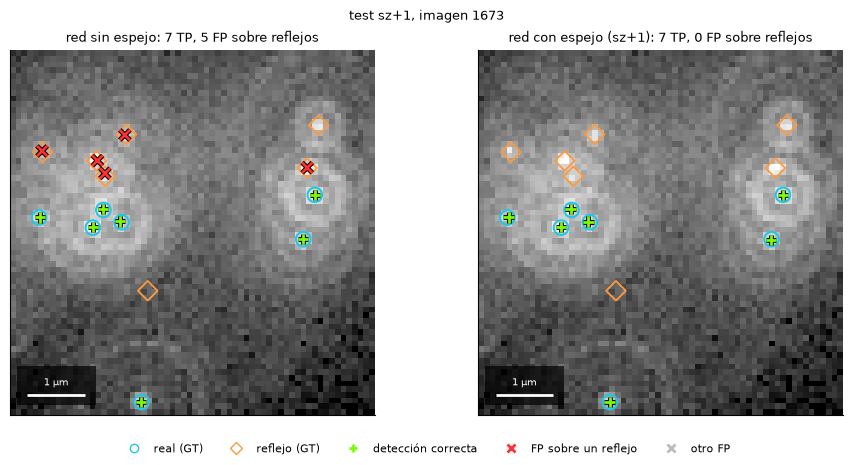

In [8]:
# ejemplo: la imagen del test sz+1 con mas FP de la red sin espejo sobre reflejos y ninguno de la red con espejo
SIGNO_EJ = +1
datos = RAIZ / "localizacion" / "datos" / f"test_espejo_sz{SIGNO_EJ:+d}"
imgs = np.load(datos / "imagenes.npy", mmap_mode="r")
cfg_t = json.load(open(datos / "config_simulador.json"))["config"]
gt_t = pd.read_csv(datos / "ground_truth.csv")
preds = {n: pd.read_csv(c / "predicciones.csv") for n, c in REDES[SIGNO_EJ]}
(n0, p0), (n1, p1) = preds.items()


def fp(p):
    return p[~p.tp & ~p.fuera_fov]


cand = (fp(p0)[fp(p0).sobre_reflejo].groupby("video_id").size().rename("fp_refl_0").to_frame()
        .join(fp(p1).groupby("video_id").size().rename("fp_1")).fillna(0)
        .join(gt_t[gt_t.en_fov].groupby("video_id").size().rename("n_reales")))
cand = cand[(cand.fp_1 == 0) & cand.n_reales.between(3, 7)].sort_values(["fp_refl_0", "n_reales"], ascending=False)
vid = int(cand.index[0])
px_t = cfg_t["pixel_camara_um"] / cfg_t["magnificacion"]           # um / px
img_e = (imgs[vid, 0].astype(float) - cfg_t["offset"]) * cfg_t["gain"]
H, W = img_e.shape
ext = extension_um(H, W, px_t)
g = gt_t[gt_t.video_id == vid]
norma = PowerNorm(0.5, vmin=np.percentile(img_e, 1), vmax=np.percentile(img_e, 99.9))

fig, axs = plt.subplots(1, 2, figsize=(9.5, 4.6))
for ax, (nombre, p) in zip(axs, preds.items()):
    p = p[p.video_id == vid]
    ax.imshow(img_e, cmap="gray", norm=norma, extent=ext, interpolation="nearest")
    gr = g[g.reflejo_en_fov]
    ax.scatter(g.x_px * px_t, g.y_px * px_t, s=110, facecolors="none", edgecolors=C_REAL, lw=1.5)
    ax.scatter(gr.x_reflejo_px * px_t, gr.y_reflejo_px * px_t, s=100, marker="D", facecolors="none",
               edgecolors=C_REFLEJO, lw=1.3)
    for sel, mk, col in ((p.tp, "+", "#7CFC00"), (~p.tp & ~p.fuera_fov & p.sobre_reflejo, "x", "#ff3030"),
                         (~p.tp & ~p.fuera_fov & ~p.sobre_reflejo, "x", "#bbbbbb")):
        s = ax.scatter(p[sel].x_px * px_t, p[sel].y_px * px_t, s=55, marker=mk, color=col, lw=2, zorder=5)
        s.set_path_effects([patheffects.withStroke(linewidth=3.5, foreground="black")])
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
    n_fpr = int((~p.tp & ~p.fuera_fov & p.sobre_reflejo).sum())
    ax.set_title(f"red {nombre}: {int(p.tp.sum())} TP, {n_fpr} FP sobre reflejos")
    ax.set_xticks([]); ax.set_yticks([])
    barra_escala(ax, ext)
fig.legend(handles=[Line2D([], [], marker="o", ls="none", mfc="none", mec=C_REAL, label="real (GT)"),
                    Line2D([], [], marker="D", ls="none", mfc="none", mec=C_REFLEJO, label="reflejo (GT)"),
                    Line2D([], [], marker="+", ls="none", color="#7CFC00", mew=2, label="detección correcta"),
                    Line2D([], [], marker="x", ls="none", color="#ff3030", mew=2, label="FP sobre un reflejo"),
                    Line2D([], [], marker="x", ls="none", color="#bbbbbb", mew=2, label="otro FP")],
           loc="lower center", ncol=5, frameon=False, fontsize=8)
fig.suptitle(f"test sz{SIGNO_EJ:+d}, imagen {vid}", fontsize=9)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

La red sin espejo detecta muchos reflejos como si fueran partículas: son el 73% (sz+1) y el 82% (sz−1) de sus FP. La red con espejo casi no comete ese error. Su precisión pasa de 0.73 y 0.55 a 0.98 en los dos tests, con un recall parecido (0.83 → 0.80 y 0.82 → 0.81). El RMSE global cambia poco: lateral 22 → 20 nm, z 68 → 65 nm (sz+1) y 68 → 63 nm (sz−1). El ejemplo se eligió como un caso típico de esa diferencia (la imagen con más FP sobre reflejos de la red sin espejo, entre las que la red con espejo no tiene FP), no como un caso promedio.

## 5. RMSE en z vs fotones, por distancia al espejo

RMSE z de los emisores detectados, por rango de distancia al plano del espejo y de fotones (los rangos de `evaluate.py`). Los IC 95% salen de un bootstrap de imágenes del test, porque los emisores de una imagen no son independientes. La red sin espejo aparece en los dos tests y cada red con espejo solo en el suyo.

La tabla de abajo da la **diferencia pareada** (con − sin espejo): el RMSE sobre los emisores que detectan las dos redes. No la afecta que cada red detecte un conjunto distinto de emisores.

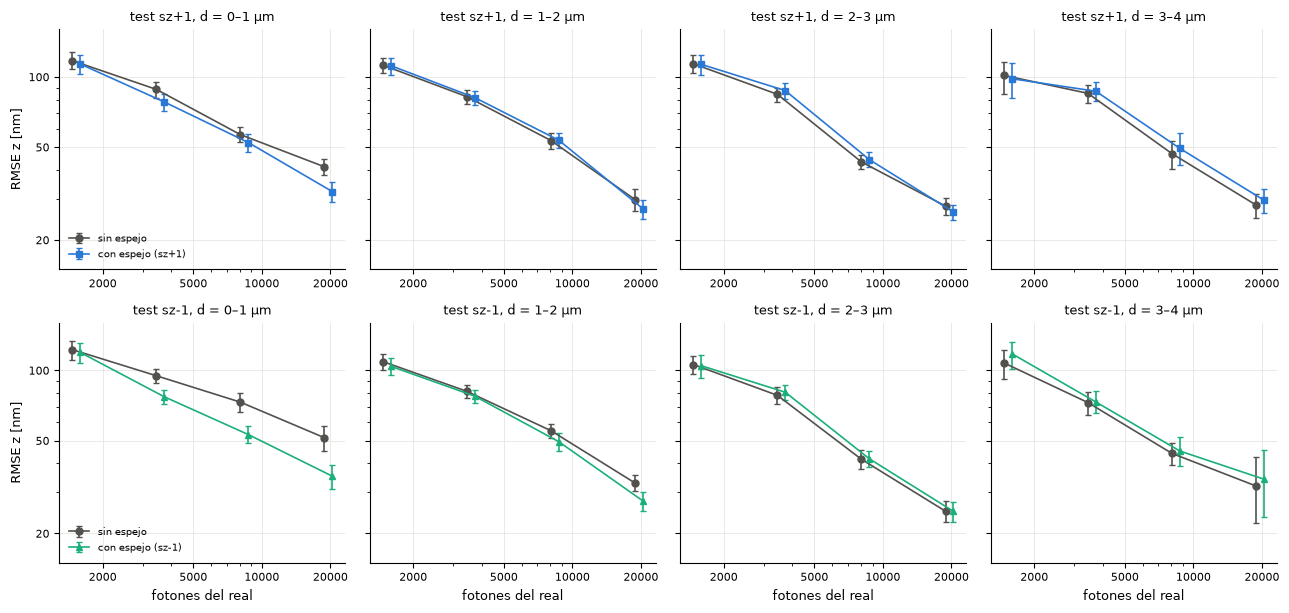

RMSE z pareado: con − sin espejo [nm], IC 95%  (* el IC excluye el 0)                   sz+1  \
d [µm] fotones                                                                                 
0–1    1.0k–2.3k                                                           -1.9 [-9.0, +5.2]   
       2.3k–5.5k                                                       -10.1 [-14.8, -5.6] *   
       5.5k–12.8k                                                        -5.3 [-8.7, -1.8] *   
       12.8k–30.0k                                                      -8.9 [-11.7, -6.4] *   
1–2    1.0k–2.3k                                                           -0.1 [-5.5, +5.3]   
       2.3k–5.5k                                                           +0.5 [-2.7, +3.6]   
       5.5k–12.8k                                                          +0.5 [-1.9, +3.0]   
       12.8k–30.0k                                                       -1.5 [-3.0, -0.0] *   
2–3    1.0k–2.3k                                                           +2.6 [-2.9, +8.3]   
       2.3k–5.5k                                                         +4.0 [+0.5, +7.6] *   
       5.5k–12.8k                                                          +1.2 [-0.7, +3.3]   
       12.8k–30.0k                                                       -1.6 [-3.3, -0.1] *   
3–4    1.0k–2.3k                                                          +4.8 [-1.1, +10.8]   
       2.3k–5.5k                                                           +3.7 [-0.9, +8.3]   
       5.5k–12.8k                                                          +1.8 [-2.9, +6.7]   
       12.8k–30.0k                                                         +1.4 [-0.9, +3.6]   

RMSE z pareado: con − sin espejo [nm], IC 95%  (* el IC excluye el 0)                    sz-1  
d [µm] fotones                                                                                 
0–1    1.0k–2.3k                                                           -9.3 [-18.9, +0.2]  
       2.3k–5.5k                                                       -17.0 [-22.4, -11.4] *  
       5.5k–12.8k                                                      -16.5 [-21.5, -11.7] *  
       12.8k–30.0k                                                     -15.5 [-19.2, -11.5] *  
1–2    1.0k–2.3k                                                           -5.7 [-11.7, +0.6]  
       2.3k–5.5k                                                          -3.5 [-6.6, -0.1] *  
       5.5k–12.8k                                                        -7.8 [-11.1, -4.9] *  
       12.8k–30.0k                                                        -5.3 [-7.4, -3.3] *  
2–3    1.0k–2.3k                                                            +3.7 [-1.8, +9.3]  
       2.3k–5.5k                                                            +3.3 [-0.2, +6.8]  
       5.5k–12.8k                                                           +0.2 [-1.7, +2.1]  
       12.8k–30.0k                                                          -0.0 [-1.2, +1.2]  
3–4    1.0k–2.3k                                                           +2.6 [-7.6, +11.9]  
       2.3k–5.5k                                                            +0.1 [-4.0, +4.4]  
       5.5k–12.8k                                                           +2.2 [-2.1, +6.8]  
       12.8k–30.0k                                                        +2.2 [+0.4, +4.3] *

In [9]:
COL = {"sin espejo": "#52514e", "con espejo (sz+1)": "#2a78d6", "con espejo (sz-1)": "#1baf7a"}
MK = {"sin espejo": "o", "con espejo (sz+1)": "s", "con espejo (sz-1)": "^"}
rng = np.random.default_rng(SEMILLA)
boot, bordes_t = {}, {}
for signo, redes in REDES.items():
    _, gt_s, _ = ce.cargar_test(RAIZ / "localizacion" / "datos" / f"test_espejo_sz{signo:+d}")
    g_fov = gt_s[gt_s.en_fov]
    bd, bf = ce.bordes(g_fov.d_espejo_nm, "lineal"), ce.bordes(g_fov.photons, "log")
    lista = [(n, pd.read_csv(c / "gt_eval.csv"), ce.con_espejo(c)) for n, c in redes]   # la sin espejo es la referencia
    boot[signo], bordes_t[signo] = ce.bootstrap_redes(lista, bd, bf, N_BOOT, rng), (bd, bf)

fig, axs = plt.subplots(2, 4, figsize=(13, 6.2), sharey=True)
for fila, (signo, redes) in enumerate(REDES.items()):
    bd, bf = bordes_t[signo]
    b = boot[signo]
    nf = len(bf) - 1
    xc = np.sqrt(bf[:-1] * bf[1:])
    for i in range(len(bd) - 1):
        ax = axs[fila, i]
        sl = slice(i * nf, (i + 1) * nf)
        for k, (nombre, _) in enumerate(redes):
            y = b[f"rmse_z_red[{nombre}]"][sl]
            lo, hi = b[f"rmse_z_red[{nombre}]_ic_lo"][sl], b[f"rmse_z_red[{nombre}]_ic_hi"][sl]
            ax.errorbar(xc * np.exp((k - 0.5) * 0.08), y, yerr=[y - lo, hi - y], fmt=MK[nombre] + "-", color=COL[nombre],
                        ms=5, lw=1.2, capsize=2, label=nombre)
        ce.formato_log(ax)
        ax.set_ylim(15, 160)
        ax.set_title(f"test sz{signo:+d}, d = {bd[i] / 1000:.0f}–{bd[i + 1] / 1000:.0f} µm")
        ax.grid(True, color="#e6e5e0", lw=0.6)
        if fila == 1:
            ax.set_xlabel("fotones del real")
        if i == 0:
            ax.set_ylabel("RMSE z [nm]")
            ax.legend(frameon=False, fontsize=7.5, loc="lower left")
fig.tight_layout()
plt.show()

filas = []
for signo, redes in REDES.items():
    bd, bf = bordes_t[signo]
    nombre = redes[1][0]
    b = boot[signo]
    for i in range(len(bd) - 1):
        for j in range(len(bf) - 1):
            k = i * (len(bf) - 1) + j
            dif = f"dif_pareada[{nombre}]"
            filas.append({"test": f"sz{signo:+d}", "i": i, "j": j, "d [µm]": f"{bd[i] / 1000:.0f}–{bd[i + 1] / 1000:.0f}",
                          "fotones": f"{bf[j] / 1000:.1f}k–{bf[j + 1] / 1000:.1f}k",
                          "dif [nm]": b[dif][k], "IC lo": b[dif + "_ic_lo"][k], "IC hi": b[dif + "_ic_hi"][k]})
dif = pd.DataFrame(filas)
dif["signif."] = np.where(dif["IC hi"] < 0, "con espejo mejor", np.where(dif["IC lo"] > 0, "con espejo peor", ""))
fmt = dif.assign(txt=[f"{r['dif [nm]']:+.1f} [{r['IC lo']:+.1f}, {r['IC hi']:+.1f}]" + (" *" if r["signif."] else "")
                      for _, r in dif.iterrows()])
tabla_dif = fmt.pivot(index=["i", "j", "d [µm]", "fotones"], columns="test", values="txt").sort_index()
display(tabla_dif.droplevel(["i", "j"]).rename_axis(columns="RMSE z pareado: con − sin espejo [nm], IC 95%  (* el IC excluye el 0)"))

**Lectura.**
- **Desde 2 µm del espejo las dos redes tienen prácticamente el mismo RMSE z:** las diferencias son de pocos nm, en los dos sentidos, y la mayoría de los IC incluye el 0.
- **Por debajo de 1 µm, y desde 2300 fotones, la red con espejo es significativamente mejor:** 5–10 nm con sz+1 y 15–17 nm con sz−1. Con sz−1 también lo es entre 1 y 2 µm. Pero su RMSE junto al espejo queda en el mismo rango que lejos de él (25–35 nm a muchos fotones). Es la red sin espejo la que empeora junto al espejo, donde el reflejo se superpone con el real.
- **Esto es consistente con que la red con espejo aprendió a ignorar el reflejo, no con que lo use para z:** si lo usara, su RMSE debería bajar justo donde el reflejo aporta información (sección 6), y no baja.
- **A pocos fotones el RMSE se calcula solo sobre los detectados** (recall ~0.35–0.45 en 1.0–2.3k fotones), así que está sesgado hacia los casos fáciles.

## 6. Cuánto podría aportar el reflejo

Cotas de Cramér-Rao en z ($\sqrt{\mathrm{CRLB}_z}$, desviación estándar mínima de un estimador insesgado) calculadas con el mismo modelo de PSF y de cámara del simulador:

- **emisor solo:** z sale solo de la forma de la PSF;
- **emisor + reflejo:** modelo conjunto con $p' = p_0 + R(p - p_0)$ y $0.8N$ fotones en el reflejo, el mismo fondo, y las PSF superpuestas cerca del espejo;
- **triangulación oráculo:** z a partir de las posiciones laterales del GT del test más ruido gaussiano (14 nm para el real; para el reflejo, su CRLB lateral según fotones y desenfoque).

Las cotas usan α = 34.0° y la triangulación usa la geometría de cada muestra del test, con RMS sobre z ∈ [−800, 800] nm y sobre el fondo del test. Los puntos son las redes de la sección 5. Los cálculos están en `figuras/crlb_espejo.py`; la versión completa, con las limitaciones al pie, en `figuras/fig_crlb_espejo_sz±1.png`.

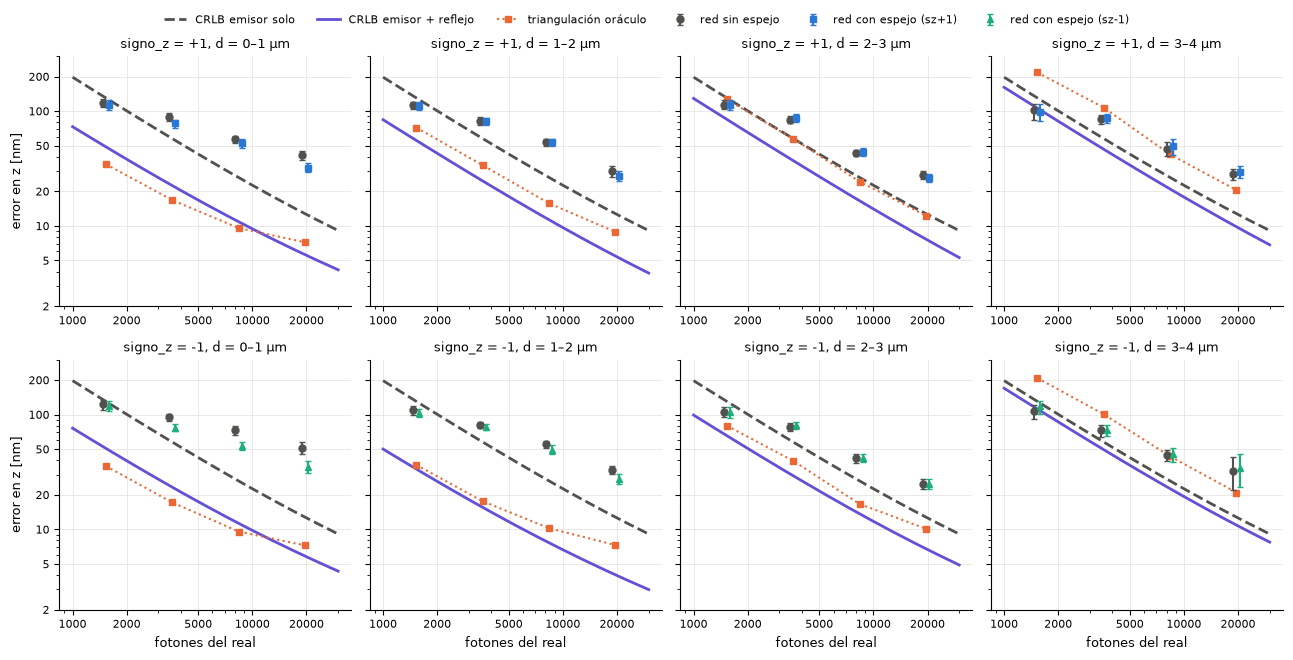

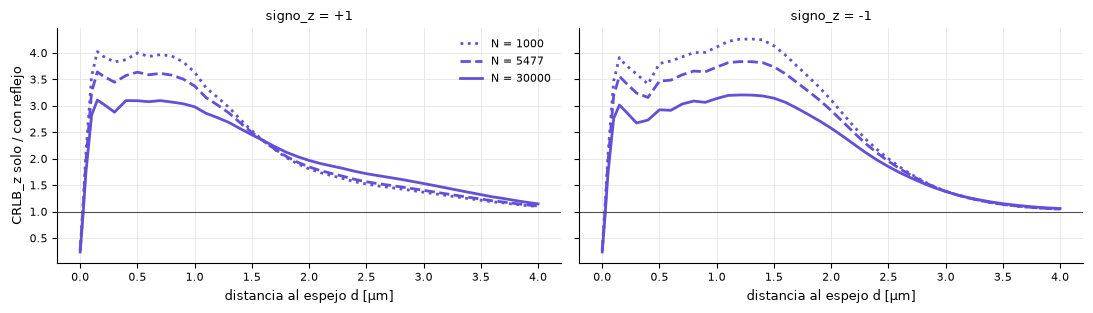

In [10]:
archivos = {s: (RAIZ / "figuras" / f"crlb_espejo_sz{s:+d}.csv", RAIZ / "figuras" / f"crlb_espejo_rangos_sz{s:+d}.csv")
            for s in (+1, -1)}
if not all(a.exists() for par in archivos.values() for a in par):
    display(Markdown("**Sección pendiente:** faltan los CSV de la CRLB. Correr "
                     "`~/miniforge3/envs/tesis/bin/python figuras/crlb_espejo.py` (~35 s) y volver a ejecutar esta celda."))
else:
    fig, axs = plt.subplots(2, 4, figsize=(13, 6.4), sharey=True)
    for fila, signo in enumerate((+1, -1)):
        crlb = pd.read_csv(archivos[signo][0])
        rangos = pd.read_csv(archivos[signo][1])
        bd, bf = bordes_t[signo]
        b = boot[signo]
        nf = len(bf) - 1
        xc = np.sqrt(bf[:-1] * bf[1:])
        for i in range(len(bd) - 1):
            ax = axs[fila, i]
            cs = ce.curva_por_fotones(crlb, bd[i], bd[i + 1], "crlb_z_solo_nm")
            cc = ce.curva_por_fotones(crlb, bd[i], bd[i + 1], "crlb_z_conjunto_nm")
            ax.plot(cs.index, cs.values, color="#52514e", lw=2, ls="--", label="CRLB emisor solo")
            ax.plot(cc.index, cc.values, color="#6250d6", lw=2, label="CRLB emisor + reflejo")
            t = rangos[np.isclose(rangos.d_desde_nm, bd[i])]
            ax.plot(xc, t.rmse_z_triangulacion_nm, "s:", color="#eb6834", ms=5, label="triangulación oráculo")
            sl = slice(i * nf, (i + 1) * nf)
            for k, (nombre, _) in enumerate(REDES[signo]):
                y = b[f"rmse_z_red[{nombre}]"][sl]
                lo, hi = b[f"rmse_z_red[{nombre}]_ic_lo"][sl], b[f"rmse_z_red[{nombre}]_ic_hi"][sl]
                ax.errorbar(xc * np.exp((k - 0.5) * 0.08), y, yerr=[y - lo, hi - y], fmt=MK[nombre], color=COL[nombre],
                            ms=5, capsize=2, label=f"red {nombre}")
            ce.formato_log(ax)
            ax.set_ylim(2, 300)
            ax.set_title(f"signo_z = {signo:+d}, d = {bd[i] / 1000:.0f}–{bd[i + 1] / 1000:.0f} µm")
            ax.grid(True, color="#e6e5e0", lw=0.6)
            if fila == 1:
                ax.set_xlabel("fotones del real")
            if i == 0:
                ax.set_ylabel("error en z [nm]")
    h1, l1 = axs[0, 0].get_legend_handles_labels()
    h2, l2 = axs[1, 0].get_legend_handles_labels()
    extra = [(h, l) for h, l in zip(h2, l2) if l not in l1]
    fig.legend(h1 + [h for h, _ in extra], l1 + [l for _, l in extra], loc="upper center", ncol=6, frameon=False,
               bbox_to_anchor=(0.5, 1.03))
    fig.tight_layout()
    plt.show()

    # ganancia de la cota con el reflejo vs d (RMS sobre z y fondo), a tres niveles de fotones
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
    for ax, signo in zip(axs, (+1, -1)):
        crlb = pd.read_csv(archivos[signo][0])
        for N, ls in ((1000.0, ":"), (5477.0, "--"), (30000.0, "-")):
            Nn = crlb.fotones.unique()[np.argmin(np.abs(crlb.fotones.unique() - N))]
            c = crlb[np.isclose(crlb.fotones, Nn)]
            r = c.groupby("d_nm").crlb_z_solo_nm.apply(ce.rms) / c.groupby("d_nm").crlb_z_conjunto_nm.apply(ce.rms)
            ax.plot(r.index / 1000, r.values, ls, color="#6250d6", lw=2, label=f"N = {Nn:.0f}")
        ax.axhline(1, color="#52514e", lw=0.8)
        ax.set_title(f"signo_z = {signo:+d}"); ax.set_xlabel("distancia al espejo d [µm]")
        ax.grid(True, color="#e6e5e0", lw=0.6)
    axs[0].set_ylabel("CRLB_z solo / con reflejo"); axs[0].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    plt.show()

**Lectura.**
- **Hasta ~1.5–2 µm del espejo, el reflejo contiene información suficiente para bajar la cota en z 2.5–4 veces.** A muchos fotones la cota pasa de ~15 nm a 4.5–6.6 nm; con `signo_z = −1` la ganancia dura algo más, porque el reflejo cae en −z, donde la PSF es más compacta. A 4 µm la ganancia es ~1.1×, porque el reflejo está desenfocado 5.8–7.4 µm.
- **La triangulación oráculo se acerca a la cota conjunta hasta ~2 µm**, y lejos del espejo es peor que la forma de la PSF sola.
- **Las redes están lejos de esas cotas.** A muchos fotones quedan ~2× por encima de la cota del emisor solo, 4–6× por encima de la cota conjunta hasta 2 µm y ~3× más lejos. A pocos fotones quedan cerca o por debajo de la cota sin reflejo, por el prior de z y por el sesgo de supervivencia.
- **La caída de la ganancia en d → 0** se debe a que real y reflejo coinciden, y la cota local pierde información sobre la distancia al espejo.

Estas cotas suponen el modelo del simulador: no incluyen el recorte de pupila del reflejo, el FOV finito ni otros emisores (sección 7). Son una indicación de cuánto podría aportar el reflejo, no una predicción del desempeño alcanzable con el sistema real.

## 7. Pendientes y supuestos

| | estado |
|---|---|
| **`signo_z`** | **Por confirmar.** Fija de qué lado del foco queda el reflejo (+z' o −z'). La PSF del código pone los anillos del lado opuesto al que se ve en el dato real; puede ser el signo o el recorte de pupila. Se decidirá con un **z-stack de una bead** (de qué lado del foco aparecen los anillos al alejarla del objetivo). Mientras tanto, las redes se entrenaron y evaluaron con los dos signos. `signo_inclinacion = +1` está confirmado. |
| **`ratio_reflejo = 0.8`** | **Supuesto**, no medido: una sola pérdida constante que agrupa reflectividad y colección. |
| **Recorte de pupila del reflejo** | **No modelado.** El espejo está a 56° del eje óptico (medido, redondeado), prácticamente arcsin(NA/n) = 55.6°, así que parte del cono de colección del reflejo no llega por el espejo. Eso le quitaría fotones, volvería asimétrica su PSF y podría desplazar su centroide con z', lo que afecta la forma del reflejo, la cota conjunta y la triangulación. |
| **Iluminación** | **Uniforme** (no se modela la hoja de luz). |
| **Espejo** | Plano, ideal (sin aberraciones ni polarización) e infinito. |
| **Uso del reflejo por la red** | **Falta el control directo**: evaluar la red con espejo sobre el mismo test con `ratio_reflejo = 0` (mismas posiciones, reflejo sin dibujar). Si su RMSE z no cambia, no usa el reflejo. Para que lo use, la propuesta es una segunda salida (mapa 2D de reflejos), emparejar real y reflejo por la coordenada a lo largo del espejo y combinar la z triangulada con la z de la forma de la PSF. |